Target SNR was: 20
Estimated SNR is:  20.03846539340515


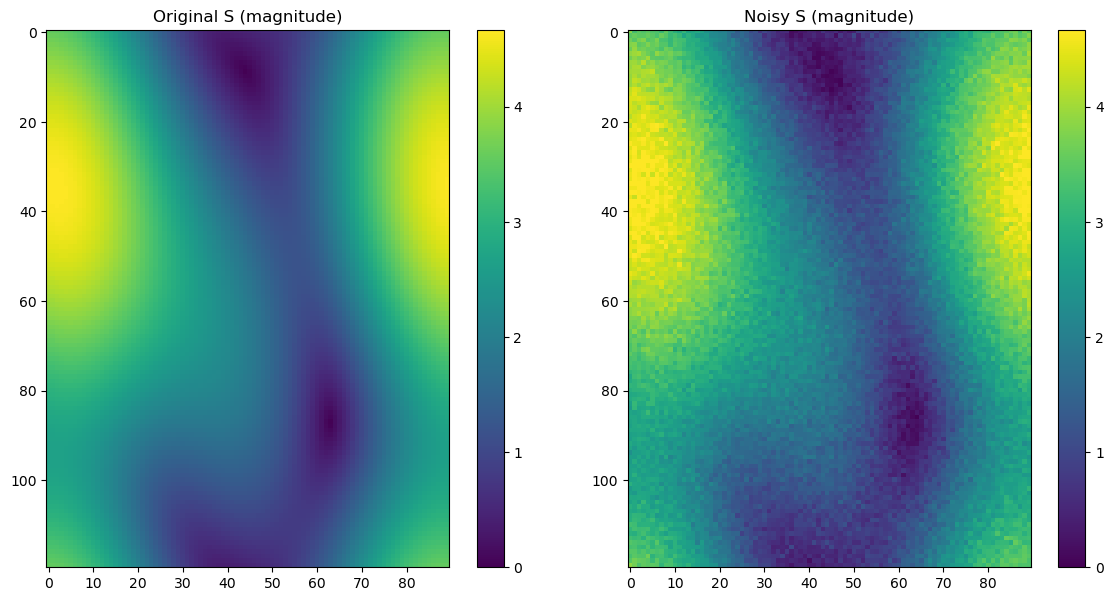

In [275]:
import numpy as np
import matplotlib.pyplot as plt
# Create grid indices
x = np.linspace(0, 2*np.pi, 120)
y = np.linspace(0, 2*np.pi, 90)
z = np.linspace(0, 2*np.pi, 30)
X, Y, Z = np.meshgrid(x, y, z, indexing='ij')

# Real part: smooth variation using a sine wave
real_part = np.sin(X) + 2*np.cos(Y) + 3*np.sin(Z)

# Imaginary part: another smooth variation (e.g., cosine wave)
imaginary_part = np.cos(X) - np.sin(Y) + np.cos(Z)

# Combine real and imaginary parts into a complex array
S = real_part + 1j * imaginary_part

SNR=20
Sf = np.fft.fftn(S,norm='ortho')
noise = (np.random.normal(0,np.mean(np.abs(S))/SNR,S.shape)+1j*np.random.normal(0,np.mean(np.abs(S))/SNR,S.shape))
S_noisy = np.fft.ifftn(Sf+noise,norm='ortho')

print('Target SNR was:', str(SNR))
print('Estimated SNR is: ',np.mean(np.abs(S))/np.std(np.abs(S)-np.abs(S_noisy)))

# Plot a slice of the real part of S and S_noisy side by side
slice_idx = 12  # Take a slice along the z-axis

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Plot original real part of S (slice)
im1 = axes[0].imshow(np.abs(S[:, :, slice_idx]), cmap='viridis',vmin=0,vmax=np.abs(S[:, :, slice_idx]).max())
axes[0].set_title('Original S (magnitude)')
plt.colorbar(im1, ax=axes[0])

# Plot real part of S_noisy (slice)
im2 = axes[1].imshow(np.abs(S_noisy[:, :, slice_idx]), cmap='viridis',vmin=0,vmax=np.abs(S[:, :, slice_idx]).max())
axes[1].set_title('Noisy S (magnitude)')
plt.colorbar(im2, ax=axes[1])

plt.tight_layout()
plt.show()